### 1. Загрузка данных

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from rink import plot_rink

sns.set_style('whitegrid')

# Первый столбец Excel - сохраненный номер строки, для анализа он не нужен
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)
print('Размер таблицы:', events.shape)
display(events.iloc[:10, [2, 3, 4, 9, 12]])
print('Матчей:', events['Game ID'].nunique())

Размер таблицы: (29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Матчей: 82


### 2. Таблица с результатами матчей

In [2]:
games = events.groupby('Game ID').agg({
    'Date': 'first',
    'Away Team': 'first',
    'Home Team': 'first',
    'Cumulated Away Score': 'max',
    'Cumulated Home Score': 'max'
})
games = games.rename(columns={
    'Cumulated Away Score': 'Away Score',
    'Cumulated Home Score': 'Home Score'
})

# Последний период показывает, сколько было овертаймов
last_period = events.groupby('Game ID')['Period'].max()
def outcome(p):
    if p == 3:
        return 'Final'
    if p == 4:
        return 'Final/OT'
    return 'Final/' + str(p - 3) + 'OT'

games['Outcome'] = last_period.apply(outcome)
display(games.tail())
print('Матчей с овертаймом:', (last_period > 3).sum())

,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,Final


Матчей с овертаймом: 22


### 3. Функция для вывода информации о матче

In [4]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, "
            f"{g['Outcome']}, {g['Date']})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


### 4. Общее число голов за матч

In [5]:
games['Total Score'] = games['Away Score'] + games['Home Score']
display(games['Total Score'].describe().round(3))

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

### 5. Распределение числа голов

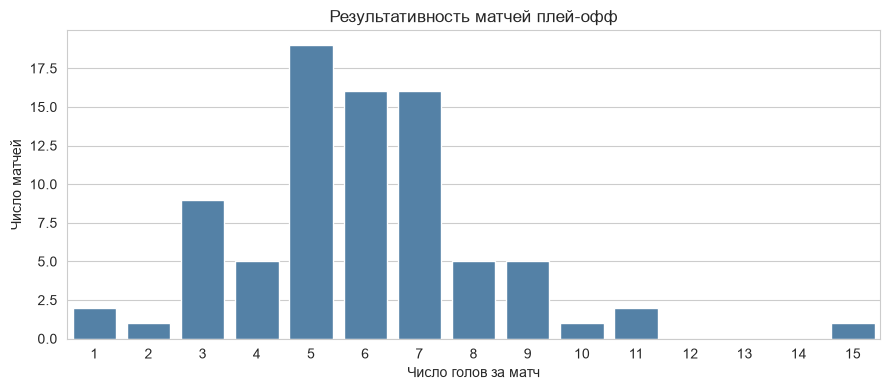

Наиболее частый результат по сумме голов: 5


In [6]:
plt.figure(figsize=(9, 4))
sns.countplot(x=games['Total Score'], color='steelblue',
              order=range(games['Total Score'].min(), games['Total Score'].max() + 1))
plt.xlabel('Число голов за матч')
plt.ylabel('Число матчей')
plt.title('Результативность матчей плей-офф')
plt.tight_layout()
plt.show()

print('Наиболее частый результат по сумме голов:', games['Total Score'].mode().iat[0])

**Вывод.** Чаще всего в матче забивали 5 голов. Основная масса игр - с 3–9 шайбами; матч с 15 шайбами заметно выделяется

### 6. Самые нерезультативные и результативные матчи

In [7]:
fewest = games[games['Total Score'] == games['Total Score'].min()].index
most = games[games['Total Score'] == games['Total Score'].max()].index
print('Минимальное число шайб:')
display([gameInfo(i) for i in fewest])
print('Максимальное число шайб:')
display([gameInfo(i) for i in most])

Минимальное число шайб:


['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

Максимальное число шайб:


['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

### 7. Сколько игроков выходило на лед в каждом матче

In [8]:
away_cols = [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)]
home_cols = [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)]
away_cols += ["Away Team's Goalie"]
home_cols += ["Home Team's Goalie"]

# На каждой стороне считаем уникальные имена. Вратарь уже может входить
# в шесть записанных игроков, поэтому повторно его не считаем
player_counts = []
for game_id, match in events.groupby('Game ID'):
    n_away = match[away_cols].stack().nunique()
    n_home = match[home_cols].stack().nunique()
    player_counts.append((game_id, n_away + n_home))

player_counts = pd.DataFrame(player_counts, columns=['Game ID', 'Player Count'])
player_counts = player_counts.set_index('Game ID')
player_counts['Game Info'] = [gameInfo(i) for i in player_counts.index]
max_players = player_counts['Player Count'].max()
display(player_counts[player_counts['Player Count'] == max_players][['Game Info', 'Player Count']])

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


### 8. Расстояние от броска до створа ворот

In [ ]:
shot_types = ['shot-on-goal', 'goal', 'missed-shot']
shots = events[events['Play Type'].isin(shot_types)].copy()

# Выбираем нужные ворота по команде и стороне защиты хозяев
home_shot = shots['Team Making the Play'] == shots['Home Team']
home_defends_left = shots["Home Team's Defending Side"] == 'left'
shots['Net X'] = np.where(home_shot == home_defends_left, 89, -89)

# Створ - от y=-3 до y=3. Берем ближайшую точку отрезка
x = shots['X Coordinate on the Ice Rink']
y = shots['Y Coordinate on the Ice Rink']
closest_y = y.clip(-3, 3)
shots['Shot Length'] = np.sqrt((x - shots['Net X'])**2 + (y - closest_y)**2)

display(shots[['Game ID', 'Play Type', 'Shot Length']].head().round(3))
print('Бросков с рассчитанной дистанцией:', shots['Shot Length'].notna().sum())

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924


Бросков с рассчитанной дистанцией: 7266


### 9. Сравнение дистанций точных и неточных бросков

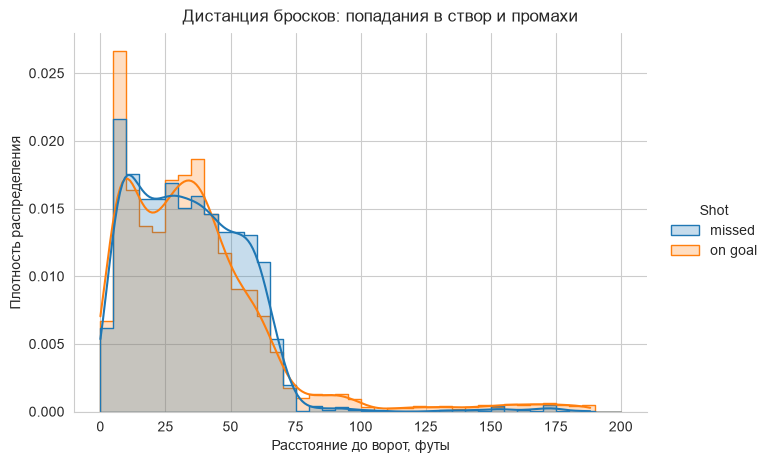

,count,mean,50%,max
Shot,,,,
missed,2643.0,34.01,32.25,185.07
on goal,4623.0,36.21,31.83,188.22


In [10]:
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')
g = sns.displot(data=shots, x='Shot Length', hue='Shot',
                bins=range(0, 201, 5), stat='density',
                common_norm=False, element='step', kde=True,
                height=4.5, aspect=1.5)
g.set_axis_labels('Расстояние до ворот, футы', 'Плотность распределения')
g.fig.suptitle('Дистанция бросков: попадания в створ и промахи', y=1.02)
plt.show()
display(shots.groupby('Shot')['Shot Length'].describe()[['count', 'mean', '50%', 'max']].round(2))

**Вывод.** Основная часть бросков обеих групп приходится на дистанции примерно до 75 футов. У точных бросков заметен длинный хвост: это могут быть дальние попытки выбросить шайбу, броски по пустым воротам или броски, которые вратарь ловит из своей зоны. Для сравнения использована плотность (`stat='density'`, `common_norm=False`), поскольку число точных и неточных бросков различается

### 10. Доля бросков в створ в каждом матче для каждой команды

In [11]:
numshots = shots.groupby(['Game ID', 'Team Making the Play', 'Shot']).size()
numshots = numshots.unstack(fill_value=0)
numshots['Share of Shots on Goal'] = numshots['on goal'] / (numshots['on goal'] + numshots['missed'])
display(numshots['Share of Shots on Goal'].head(10).round(3))
display(numshots['Share of Shots on Goal'].describe().round(3))

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
            Buffalo Sabres          0.682
2025030114  Boston Bruins           0.600
            Buffalo Sabres          0.648
2025030115  Boston Bruins           0.630
            Buffalo Sabres          0.491
Name: Share of Shots on Goal, dtype: float64

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

**Вывод.** Средняя доля за один матч одной команды - около 64%. Показатель заметно меняется от игры к игре (примерно от 35% до 86%). Заблокированные броски в знаменатель не включались; голы учитывались как попадания в створ

### 11. Пять команд с самой высокой и самой низкой точностью

In [12]:
avgnumshots = numshots.groupby(level='Team Making the Play')['Share of Shots on Goal'].mean()
print('Пять лучших:')
display(avgnumshots.nlargest(5).round(3))
print('Пять последних:')
display(avgnumshots.nsmallest(5).round(3))

Пять лучших:


Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

Пять последних:


Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

**Вывод.** Самая высокая средняя доля у Edmonton Oilers (70,6%), самая низкая - у Pittsburgh Penguins (55,4%). Это доля попаданий в створ, а не эффективность реализации моментов. Здесь для каждой команды сначала вычислена доля в каждом матче, а потом взято среднее по матчам

### 12. Среднее число попаданий в створ и голов у каждой команды

In [13]:
# Составляем полный список пар «игра - команда» по две строки на матч
team_games = pd.concat([
    games[['Away Team']].rename(columns={'Away Team': 'Team'}),
    games[['Home Team']].rename(columns={'Home Team': 'Team'})
]).reset_index().set_index(['Game ID', 'Team'])

sog = shots[shots['Shot'] == 'on goal'].groupby(['Game ID', 'Team Making the Play']).size()
goals_team = events[events['Play Type'] == 'goal'].groupby(['Game ID', 'Team Making the Play']).size()
team_games['Shot'] = sog
team_games['Goal'] = goals_team
team_games = team_games.fillna(0)
avgshots = team_games.groupby(level='Team')[['Shot', 'Goal']].mean()
display(avgshots.round(3))

,Shot,Goal
Team,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


### 13. Есть ли связь между бросками в створ и голами?

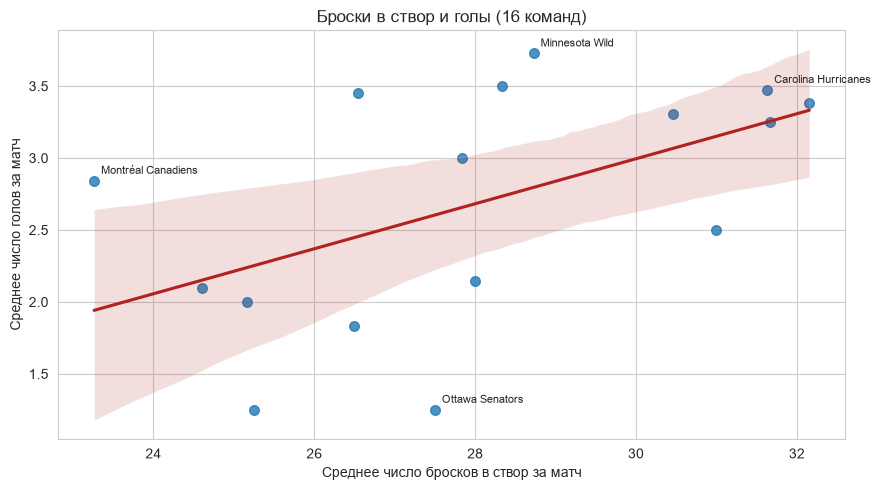

Корреляция Пирсона: 0.521


In [14]:
plt.figure(figsize=(9, 5))
sns.regplot(data=avgshots, x='Shot', y='Goal', ci=95,
            scatter_kws={'s': 48}, line_kws={'color': 'firebrick'})
plt.xlabel('Среднее число бросков в створ за матч')
plt.ylabel('Среднее число голов за матч')
plt.title('Броски в створ и голы (16 команд)')
for team in ['Minnesota Wild', 'Carolina Hurricanes', 'Ottawa Senators', 'Montréal Canadiens']:
    r = avgshots.loc[team]
    plt.annotate(team, (r['Shot'], r['Goal']),
                 xytext=(5, 5), textcoords='offset points', fontsize=8)
plt.tight_layout()
plt.show()
print('Корреляция Пирсона:', round(avgshots['Shot'].corr(avgshots['Goal']), 3))

**Вывод.** Положительная связь есть, но она не очень сильная: корреляция примерно 0,52. Команды, чаще попадающие в створ, в среднем забивают больше, но отдельные команды сильно отклоняются от линии. На результативность влияет не только число бросков, но и их качество, игра вратарей и другие факторы

### 14. Матч с наибольшим числом всех бросков

In [15]:
all_shot_types = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
all_shots = events[events['Play Type'].isin(all_shot_types)]
shots_by_game = all_shots.groupby('Game ID').size()
idxmax = shots_by_game.idxmax()
print(gameInfo(idxmax))
print('Всего бросков (включая блокированные):', shots_by_game.max())

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Всего бросков (включая блокированные): 208


### 15. Откуда наносили броски в этом матче

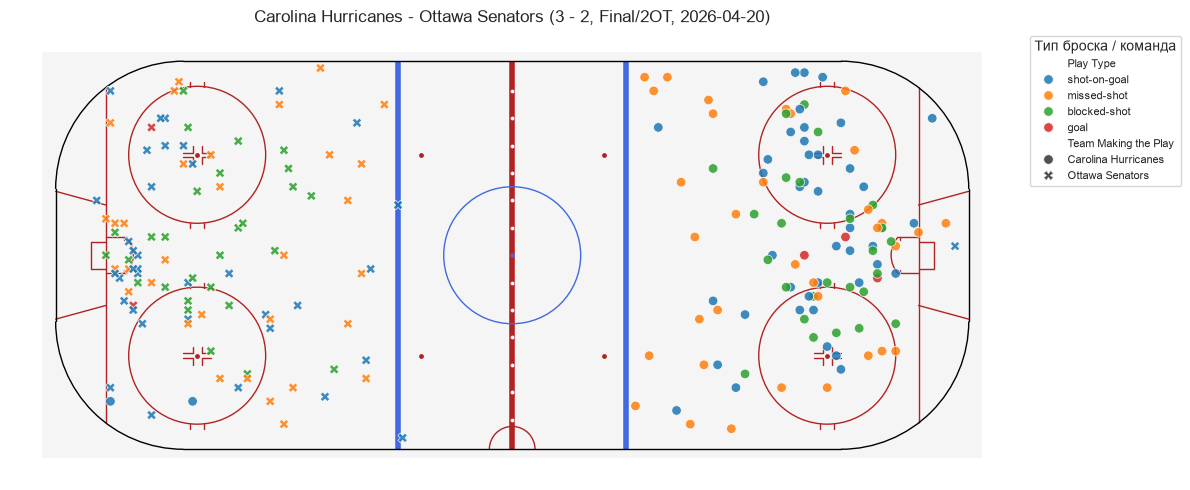

In [ ]:
match_shots = all_shots[all_shots['Game ID'] == idxmax].copy()
match_shots['Plot X'] = match_shots['X Coordinate on the Ice Rink']
match_shots['Plot Y'] = match_shots['Y Coordinate on the Ice Rink']

# В нечетных периодах разворачиваем координаты на 180 градусов
odd_period = match_shots['Period'] % 2 == 1
match_shots.loc[odd_period, ['Plot X', 'Plot Y']] *= -1

plt.figure(figsize=(12, 5))
plot_rink()
sns.scatterplot(data=match_shots, x='Plot X', y='Plot Y',
                hue='Play Type', style='Team Making the Play',
                s=47, alpha=0.85)
plt.title(gameInfo(idxmax))
plt.xlim(-105, 105)
plt.ylim(-47, 47)
plt.axis('equal')
plt.axis('off')
plt.legend(title='Тип броска / команда', bbox_to_anchor=(1.01, 1),
           loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

### 16. Десять лучших снайперов

In [17]:
goal_events = events[events['Play Type'] == 'goal']
scorers = goal_events['Player in the Event #1'].value_counts()
display(scorers.head(10).rename('Голы').to_frame())

,Голы
Player in the Event #1,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Nikolaj Ehlers,8
Jordan Staal,8
Alex Newhook,7
Taylor Hall,7
Jackson Blake,7


### 17. Десять лучших ассистентов

In [18]:
assists = pd.concat([
    goal_events['Player in the Event #2'],
    goal_events['Player in the Event #3']
]).dropna().value_counts()
display(assists.head(10).rename('Передачи').to_frame())

,Передачи
Jack Eichel,20
Mitch Marner,19
Lane Hutson,13
Jackson Blake,13
Nick Suzuki,12
Taylor Hall,12
Martin Necas,12
Shea Theodore,12
Kirill Kaprizov,11
Quinn Hughes,11


### 18. Десять лучших по системе гол + пас

In [19]:
points = scorers.add(assists, fill_value=0).astype(int)
points = points.sort_values(ascending=False)
display(points.head(10).rename('Очки').to_frame())

,Очки
Player in the Event #1,
Mitch Marner,29
Jack Eichel,22
Jackson Blake,20
Taylor Hall,19
Brett Howden,18
Nikolaj Ehlers,18
Shea Theodore,18
Pavel Dorofeyev,16
Lane Hutson,16


### 19. Десять игроков по средним броскам в створ за игру

In [ ]:
# Считаем, сколько матчей реально провел каждый игрок,по спискам на льду
player_games_rows = []
for game_id, match in events.groupby('Game ID'):
    for side, cols in [('Away', away_cols), ('Home', home_cols)]:
        for player in match[cols].stack().unique():
            player_games_rows.append((game_id, player))
player_games = pd.DataFrame(player_games_rows, columns=['Game ID', 'Player'])
player_games = player_games.drop_duplicates()
games_played = player_games.groupby('Player')['Game ID'].nunique()

# Гол, тоже попадание в створ
players_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
shot_counts = players_shots['Player in the Event #1'].value_counts()
shots_per_game = (shot_counts / games_played).dropna().sort_values(ascending=False)
player_shot_table = pd.DataFrame({
    'Броски в створ': shot_counts,
    'Матчи': games_played,
    'За матч': shots_per_game
}).loc[shots_per_game.head(10).index]
display(player_shot_table.round(3))

,Броски в створ,Матчи,За матч
Player in the Event #1,,,
Jason Robertson,30.0,6,5.000
Dylan Guenther,27.0,6,4.500
Nikita Kucherov,31.0,7,4.429
Matt Boldy,48.0,11,4.364
Quinton Byfield,17.0,4,4.250
Darren Raddysh,28.0,7,4.000
Joel Eriksson Ek,24.0,6,4.000
Alex Laferriere,15.0,4,3.750
David Pastrnak,22.0,6,3.667


### 20. Десять игроков по средним силовым приемам за игру

In [24]:
hit_counts = events.loc[events['Play Type'] == 'hit', 'Player in the Event #1'].value_counts()
hits_per_game = (hit_counts / games_played).dropna().sort_values(ascending=False)
player_hit_table = pd.DataFrame({
    'Силовые приемы': hit_counts,
    'Матчи': games_played,
    'За матч': hits_per_game
}).loc[hits_per_game.head(10).index]
display(player_hit_table.round(3))

,Силовые приемы,Матчи,За матч
Player in the Event #1,,,
Lawson Crouse,38.0,6,6.333
Alex Turcotte,6.0,1,6.000
Alexander Petrovic,6.0,1,6.000
Yakov Trenin,51.0,9,5.667
Dylan Cozens,22.0,4,5.500
Vasily Podkolzin,32.0,6,5.333
Marcus Foligno,55.0,11,5.000
Ivan Barbashev,110.0,22,5.000
Carl Grundstrom,15.0,3,5.000


### 21. Вратари, не пропускавшие голов хотя бы в одном из матчей

In [22]:
# Все пары «матч - вратарь», где вратарь находился на льду
goalies_played = pd.concat([
    events[['Game ID', "Away Team's Goalie"]].rename(columns={"Away Team's Goalie": 'Goalie'}),
    events[['Game ID', "Home Team's Goalie"]].rename(columns={"Home Team's Goalie": 'Goalie'})
]).dropna().drop_duplicates()

# В момент гола смотрим именно вратаря команды, которая пропустила
scored = goal_events.copy()
scored['Conceding Goalie'] = np.where(
    scored['Team Making the Play'] == scored['Home Team'],
    scored["Away Team's Goalie"], scored["Home Team's Goalie"]
)
conceded = scored.dropna(subset=['Conceding Goalie'])
conceded = conceded.groupby(['Game ID', 'Conceding Goalie']).size()
conceded.index = conceded.index.set_names(['Game ID', 'Goalie'])

by_goalie = goalies_played.set_index(['Game ID', 'Goalie'])
by_goalie['Goals Against'] = conceded
by_goalie['Goals Against'] = by_goalie['Goals Against'].fillna(0).astype(int)
clean_appearances = by_goalie[by_goalie['Goals Against'] == 0].reset_index()
display(clean_appearances.sort_values(['Goalie', 'Game ID']))
print('Всего вратарей:', clean_appearances['Goalie'].nunique())
print('Список:', ', '.join(sorted(clean_appearances['Goalie'].unique())))

,Game ID,Goalie,Goals Against
0,2025030126,Andrei Vasilevskiy,0
2,2025030146,Arturs Silovs,0
4,2025030413,Brandon Bussi,0
5,2025030416,Brandon Bussi,0
1,2025030142,Dan Vladar,0
9,2025030146,Dan Vladar,0
8,2025030131,Frederik Andersen,0
10,2025030221,Frederik Andersen,0
3,2025030314,Frederik Andersen,0
7,2025030126,Jakub Dobes,0


Всего вратарей: 8
Список: Andrei Vasilevskiy, Arturs Silovs, Brandon Bussi, Dan Vladar, Frederik Andersen, Jakub Dobes, Joonas Korpisalo, Scott Wedgewood


### 22. Дополнительный вопрос: зависит ли реализация бросков в створ от дистанции?

Посмотрим, какая доля попаданий в створ оказалась голами на разных расстояниях. В знаменателе только `shot-on-goal` и `goal`: промахи не учитываем. Для наглядности разобьем дистанцию на четыре группы

,Голы,Броски в створ,Доля голов
Distance group,,,
0–15,205,1162,0.176
15–30,139,1016,0.137
30–60,113,1851,0.061
>60,29,594,0.049


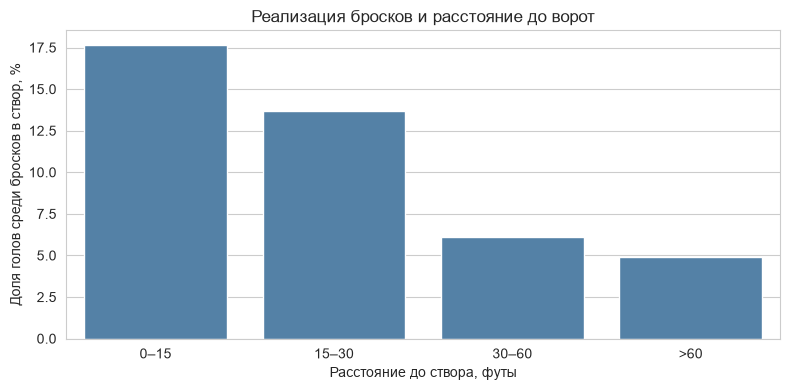

In [ ]:
on_target = shots[shots['Play Type'].isin(['shot-on-goal', 'goal'])].copy()
on_target['Distance group'] = pd.cut(
    on_target['Shot Length'], bins=[-0.01, 15, 30, 60, 200],
    labels=['0–15', '15–30', '30–60', '>60']
)
on_target['Is goal'] = on_target['Play Type'] == 'goal'
conversion = on_target.groupby('Distance group', observed=False)['Is goal'].agg(['sum', 'count', 'mean'])
conversion.columns = ['Голы', 'Броски в створ', 'Доля голов']
display(conversion.round(3))

plt.figure(figsize=(8, 4))
sns.barplot(x=conversion.index.astype(str), y=100 * conversion['Доля голов'],
            color='steelblue')
plt.xlabel('Расстояние до створа, футы')
plt.ylabel('Доля голов среди бросков в створ, %')
plt.title('Реализация бросков и расстояние до ворот')
plt.tight_layout()
plt.show()

**Вывод.** На дистанции до 15 футов голами закончились примерно 17,6% попаданий в створ, а дальше 60 футов - около 4,9%. Таким образом, с ростом расстояния реализация падает. Это описательная зависимость: здесь не учитываются ситуация на площадке, тип броска, выходы один на один и пустые ворота